In [1]:
import numpy as np 
import matplotlib.pyplot as plt


from sdp import optimal_recovery
from codes import leung_isometry
from channels import noisy_kraus_operator
from recovery import baseline_recovery_kraus
from petz import completed_petz_kraus
from fidelity import entanglement_fidelity

In [2]:
V =leung_isometry()
bits = [format(i, '04b') for i in range(16)]
noisy_kraus = lambda gamma : [noisy_kraus_operator(bit, gamma) for bit in bits]
noisy_encoding_kraus = lambda gamma : [N@V for N in noisy_kraus(gamma)]
R = baseline_recovery_kraus()
R_til = lambda gamma : completed_petz_kraus(np.eye(2)/2 , gamma)
baseline_recov = lambda gamma : [r@E for r in R for E in noisy_encoding_kraus(gamma)]
petz_recove = lambda gamma : [r_til@E for r_til in R_til(gamma) for E in noisy_encoding_kraus(gamma)]


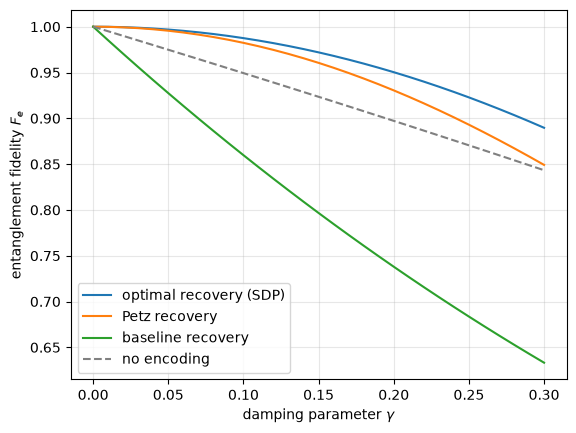

In [3]:

GAMMAS = np.linspace(0, 0.3, 31)    

f_none = (1 + np.sqrt(1 - np.array(GAMMAS)))**2 / 4

fidelity_baseline = [entanglement_fidelity(baseline_recov(gamma)) for gamma in GAMMAS]
fidelity_petz = [entanglement_fidelity(petz_recove(gamma)) for gamma in GAMMAS]
fidelity_opti = [optimal_recovery(gamma)[0] for gamma in GAMMAS]

data = np.column_stack([GAMMAS, fidelity_baseline, fidelity_petz, fidelity_opti])
np.savetxt("../data/fidelities.csv", data, delimiter=",",
           header="gamma,baseline,petz,sdp", comments="", fmt="%.10f")

plt.plot(GAMMAS, fidelity_opti, label="optimal recovery (SDP)")
plt.plot(GAMMAS, fidelity_petz, label="Petz recovery")
plt.plot(GAMMAS, fidelity_baseline, label="baseline recovery")
plt.plot(GAMMAS, f_none, "--", color="gray", label="no encoding")
plt.xlabel(r"damping parameter $\gamma$")
plt.ylabel(r"entanglement fidelity $F_e$")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../figures/opti_sdp_fidelity.png", dpi=200, bbox_inches="tight")
plt.show()

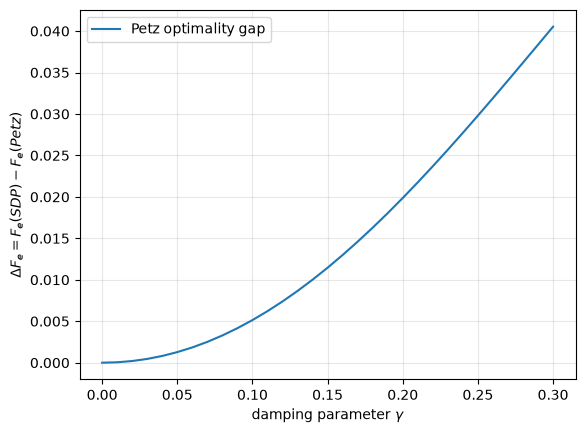

In [4]:
optimality_gap = np.array(fidelity_opti) - np.array(fidelity_petz)

plt.plot(GAMMAS, optimality_gap, label="Petz optimality gap")

plt.xlabel(r"damping parameter $\gamma$")
plt.ylabel(r"$\Delta F_e = F_e(SDP) - F_e(Petz)$")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../figures/petz_optimality_gap.png", dpi=200, bbox_inches="tight")
plt.show()

## Discussion: Petz vs. SDP-optimal recovery

*Numbers from `data/fidelities.csv` (31 values of $\gamma$ between 0 and 0.3).*

### 1. How close is Petz recovery to the SDP optimum?

Very close. The gap $F_{\text{SDP}} - F_{\text{Petz}}$ is about $5\times10^{-5}$ at $\gamma = 0.01$, $0.005$ at $\gamma = 0.1$ and $0.04$ at $\gamma = 0.3$.

A better way to compare them is the infidelity $1 - F$. For small $\gamma$:

$$1 - F_{\text{Petz}} \approx 1.75\,\gamma^2, \qquad 1 - F_{\text{SDP}} \approx 1.25\,\gamma^2,$$

so Petz loses about **1.4 times** more fidelity than the best possible recovery, at every $\gamma$ tested. It is not optimal, but it is within a constant factor of optimal.

### 2. Does the optimality gap increase or decrease as $\gamma$ changes?

It **increases** with $\gamma$. Since both infidelities grow like $\gamma^2$, the gap grows like $(1.75 - 1.25)\,\gamma^2 = 0.5\,\gamma^2$: tiny for weak noise, and noticeable (0.04) at $\gamma = 0.3$. The *ratio* of the infidelities stays almost constant ($\approx 1.4$, dropping slightly to 1.37 at $\gamma = 0.3$).

